# 🏭 Production Line Digital Twin — Part 1: Simulation
A virtual production line with 4 stations: **Cutting → Welding → Painting → Inspection**.
One 8-hour shift will be simulated and find the **bottleneck** will be found (the slowest station that holds everything up).


### Imports
- `simpy`: discrete-event simulation. The clock jumps from one event to the next (a part arrives, a machine finishes) instead of ticking every second.
- `random`: random arrival and processing times.
- `pandas` for tables, `matplotlib` for charts, `os` for folders.

In [1]:
import simpy
import random
import os
import pandas as pd
import matplotlib.pyplot as plt

### Factory settings
Parts arrive on average every 5 min, so the **arrival rate** is $\lambda = 1/5 = 0.2$ parts/min.

A station with average processing time $t$ is busy for a share of the time equal to its **utilization**:

$$\rho = \frac{\text{processing time}}{\text{arrival interval}} = \lambda \cdot t$$

| Station | $t$ (min) | $\rho = t/5$ |
|---|---|---|
| Cutting | 4 | 0.8 |
| Welding | 6 | **1.2** |
| Painting | 5 | 1.0 |
| Inspection | 3 | 0.6 |

$\rho > 1$ means work arrives faster than the station can handle it, so Welding's queue keeps growing. That makes Welding the expected bottleneck.

In [2]:
RANDOM_SEED = 42          # a fixed seed gives the same "random" results every run, so it's reproducible
SIM_TIME = 8 * 60         # simulate one 8-hour shift = 480 minutes
ARRIVAL_INTERVAL = 5      # on average, a new raw part arrives every 5 minutes

# Each station and its AVERAGE processing time in minutes.
# The dictionary keeps the order, so parts visit the stations in this order.
STATIONS = {
    "Cutting":    4,
    "Welding":    6,   # 👀 slower than parts arrive (every 5 min)
    "Painting":   5,
    "Inspection": 3,
}

### The life of one part
Each part visits the stations in order. At each one it:
1. requests the machine and waits in the queue until it's free,
2. is processed for a random time $\sim \text{Uniform}(0.8t,\ 1.2t)$, which averages $t$,
3. logs its times.

$$\text{wait time} = \text{start time} - \text{arrival time}$$

`yield` pauses this part until the event happens, and the other parts keep moving in the meantime.

In [3]:
def part(env, part_id, machines, log):
    """
    The life of one part: it visits every station in order.
    At each station it:
      1. joins the queue
      2. waits until the machine is free
      3. gets processed (takes some time)
      4. moves on to the next station
    """
    for station_name, avg_time in STATIONS.items():
        machine = machines[station_name]
        arrival_time = env.now                 # env.now = the current simulation clock (minutes)

        # request() = "I want to use this machine". The 'with' block releases it automatically when done.
        with machine.request() as request:
            yield request                      # WAIT here until the machine is free
            start_time = env.now

            # Processing time varies ±20% around the average (real machines vary a bit)
            process_time = random.uniform(avg_time * 0.8, avg_time * 1.2)
            yield env.timeout(process_time)    # the machine is busy for this long
            end_time = env.now

        # Write down what happened, like a factory logbook
        log.append({
            "part_id":      part_id,
            "station":      station_name,
            "arrival_time": arrival_time,
            "start_time":   start_time,
            "end_time":     end_time,
            "wait_time":    start_time - arrival_time,   # time spent in the queue
            "process_time": process_time,                # time spent on the machine
        })

### Part generator
The time between arrivals is drawn from an **exponential distribution** with mean 5 min. `expovariate` takes the *rate*, so we pass $\lambda = 1/5$.

Exponential gaps give random (Poisson) arrivals: sometimes several parts come close together, sometimes there are long gaps. Expected arrivals in a shift: $480 / 5 = 96$ parts.

Each new part becomes its own simpy process, so many parts move through the line at the same time.

In [4]:
def part_generator(env, machines, log):
    """Keeps creating new parts at random intervals, forever (until the simulation stops)."""
    part_id = 0
    while True:
        # Wait a random time before the next part arrives (average = ARRIVAL_INTERVAL)
        yield env.timeout(random.expovariate(1 / ARRIVAL_INTERVAL))
        part_id += 1
        # Start this new part's journey. It runs "in parallel" with all other parts.
        env.process(part(env, part_id, machines, log))

### Build the factory and run it
- `random.seed(42)` makes the run reproducible.
- Each station is a `simpy.Resource` with `capacity=1`, meaning one part at a time.
- `env.run(until=480)` simulates one 8-hour shift.

In [5]:
random.seed(RANDOM_SEED)

env = simpy.Environment()      # the simulation world with its own clock

# Create one machine per station. capacity=1 means it handles one part at a time.
machines = {name: simpy.Resource(env, capacity=1) for name in STATIONS}

log = []                       # empty logbook, filled during the simulation

env.process(part_generator(env, machines, log))   # start the part supply
env.run(until=SIM_TIME)                            # ▶ run for 480 simulated minutes

print(f"Simulation finished at minute {env.now}")
print(f"Logbook entries: {len(log)}")

Simulation finished at minute 480
Logbook entries: 290


### Results table
Turn the log (a list of dicts) into a DataFrame. Each row is one part at one station.

A product is **finished** once it has left Inspection, so we count unique `part_id`s there. Welding can do at most $480/6 = 80$ parts per shift, so the result can't be higher than that (minus the time the line takes to fill up).

In [6]:
# Turn the logbook (a list of dictionaries) into a table
df = pd.DataFrame(log)

# Parts that passed the LAST station (Inspection) are finished products
finished = df[df["station"] == "Inspection"]["part_id"].nunique()
print(f"✅ Finished products in one shift: {finished}")

df.head(10)   # show the first 10 rows

✅ Finished products in one shift: 71


,part_id,station,arrival_time,start_time,end_time,wait_time,process_time
0,1,Cutting,5.100301,5.100301,8.740348,0.000000,3.640047
1,2,Cutting,5.226946,8.740348,13.367836,3.513403,4.627487
2,1,Welding,8.740348,8.740348,15.164427,0.000000,6.424079
3,3,Cutting,6.489877,13.367836,17.242911,6.877959,3.875075
4,1,Painting,15.164427,15.164427,19.217499,0.000000,4.053072
5,2,Welding,13.367836,15.164427,20.441637,1.796591,5.277210
6,4,Cutting,13.157840,17.242911,21.482726,4.085071,4.239815
7,1,Inspection,19.217499,19.217499,21.882028,0.000000,2.664529
8,5,Cutting,13.612602,21.482726,24.693124,7.870124,3.210398
9,2,Painting,20.441637,20.441637,25.620169,0.000000,5.178531


### Quick statistics
`describe()` shows count, mean, standard deviation, min, quartiles and max for every numeric column.

In [7]:
df.describe()   # show some statistics about the numbers in the table

,part_id,arrival_time,start_time,end_time,wait_time,process_time
count,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000
mean,36.779310,224.218096,229.342068,233.817344,5.123972,4.475276
std,21.014896,137.818115,135.289453,135.310256,10.181256,1.236174
min,1.000000,5.100301,5.100301,8.740348,0.000000,2.404255
25%,19.000000,101.279269,112.566072,116.982259,0.000000,3.497449
50%,37.000000,220.999244,226.641793,230.403949,0.000000,4.421875
75%,55.000000,340.830711,342.692573,346.296443,4.033987,5.265099
max,76.000000,476.321291,476.591719,479.794425,43.785356,7.194090


### Per-station summary
Group the rows by station:
- `parts_processed`: number of parts that finished the station
- `avg_wait_min`: mean time in the queue
- `busy_time_min`: total processing time, $\sum \text{process time}$

$$\text{Utilization (\%)} = \frac{\sum \text{process time}}{\text{shift length } (480)} \times 100$$

In [8]:
# Group the rows by station and calculate statistics for each one
summary = df.groupby("station").agg(
    parts_processed=("part_id", "count"),
    avg_wait_min=("wait_time", "mean"),
    avg_process_min=("process_time", "mean"),
    busy_time_min=("process_time", "sum"),
)

# Utilization = % of the shift the machine was busy
summary["utilization_%"] = summary["busy_time_min"] / SIM_TIME * 100

summary = summary.reindex(STATIONS.keys()).round(1)   # line order instead of alphabetical, 1 decimal
summary

,parts_processed,avg_wait_min,avg_process_min,busy_time_min,utilization_%
station,,,,,
Cutting,76,4.2,4.0,304.8,63.5
Welding,72,16.1,6.0,433.9,90.4
Painting,71,0.1,4.9,345.1,71.9
Inspection,71,0.0,3.0,214.0,44.6


### Find the bottleneck
The bottleneck is the station with the highest utilization (`idxmax` returns its name). The parts queuing in front of it have the longest waits.

In [9]:
# The bottleneck is usually the busiest machine (highest utilization)
bottleneck = summary["utilization_%"].idxmax()
print(f"🚨 Bottleneck station: {bottleneck}")
print(f"   Utilization: {summary.loc[bottleneck, 'utilization_%']}%")
print(f"   Parts waiting AT it spend on average {summary.loc[bottleneck, 'avg_wait_min']} min in the queue")

🚨 Bottleneck station: Welding
   Utilization: 90.4%
   Parts waiting AT it spend on average 16.1 min in the queue


### Charts
Left: how busy each machine was. Right: the average queue time in front of each station. The bottleneck is high in both.

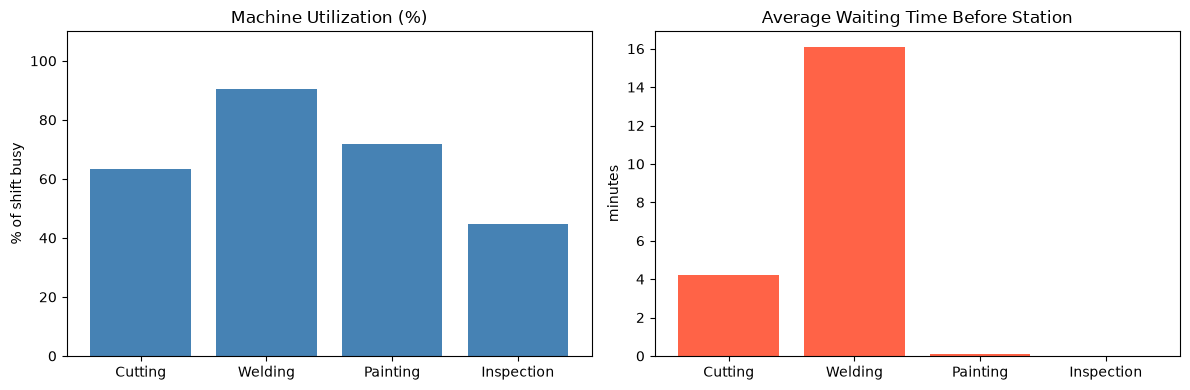

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))   # two charts side by side

# Left chart: how busy each machine is
axes[0].bar(summary.index, summary["utilization_%"], color="steelblue")
axes[0].set_title("Machine Utilization (%)")
axes[0].set_ylabel("% of shift busy")
axes[0].set_ylim(0, 110)

# Right chart: how long parts wait before each station
axes[1].bar(summary.index, summary["avg_wait_min"], color="tomato")
axes[1].set_title("Average Waiting Time Before Station")
axes[1].set_ylabel("minutes")

plt.tight_layout()
os.makedirs("../images", exist_ok=True)
plt.savefig("../images/01_utilization_and_wait.png", dpi=120)   # saved for your README later
plt.show()

### Save the log
Write the full logbook to `data/simulation_log.csv` so other notebooks can reuse it.

In [11]:
# ".." means "go up one folder" (from notebooks/ to the project folder)
os.makedirs("../data", exist_ok=True)
df.to_csv("../data/simulation_log.csv", index=False)
print("Saved to data/simulation_log.csv 💾")

Saved to data/simulation_log.csv 💾


## 📝 Conclusions
- **Welding is the bottleneck.** It is busy **90.4%** of the shift, and parts wait **16.1 min** on average in front of it. Parts arrive every 5 min, but Welding needs 6 min per part, so its queue keeps growing.
- Only **71 products** were finished in one shift, even though 76 parts entered the line. Welding caps the output at $480 / 6 = 80$ parts per shift.
- The stations after Welding are underused: Painting is busy 71.9% and Inspection only 44.6% of the time. They are waiting for parts from Welding.
- Speeding up any other station would not raise output. Only Welding's capacity matters, and Part 4 tests ways to improve it.